# Sel [1]: Setup Path & Memuat Predictor

In [1]:
import os
import sys

# Pastikan root proyek terbaca
ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT_DIR not in sys.path:
  sys.path.insert(0, ROOT_DIR)

import matplotlib.pyplot as plt
import pandas as pd
from src.ml.inference import predictor

print("=" * 70)
print(f"Perangkat Aktif : {predictor.device}")
print(f"Jumlah Model    : {len(predictor.models)} Checkpoint Terpasang")
print(f"Seed Konsensus  : {predictor.loaded_seeds}")
print("=" * 70)

e:\SEMESTER 5\TA\PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--> [AI Core] Inisialisasi Tokenizer IndoBERT: indobenchmark/indobert-base-p1...


--> [AI Core] Menemukan 3 checkpoint model untuk konsensus ansambel:
    - Memuat seed 42 dari: e:\SEMESTER 5\TA\PROJECT\ckpt_ce_42.pt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 27692.98it/s]


    - Memuat seed 123 dari: e:\SEMESTER 5\TA\PROJECT\ckpt_ce_123.pt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23981.91it/s]


    - Memuat seed 999 dari: e:\SEMESTER 5\TA\PROJECT\ckpt_ce_999.pt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 22547.58it/s]

✅ [AI Core] Berhasil mengaktifkan konsensus 3 seed IndoBERT di perangkat: cpu
--> [AI Core] Menginisialisasi Mesin LIME Text Explainer (Reproducible)...
Perangkat Aktif : cpu
Jumlah Model    : 3 Checkpoint Terpasang
Seed Konsensus  : [42, 123, 999]


# 2: Uji Inferensi 3 Skenario Nyata (Fakta, Hoaks, dan OCR Bersambung)

In [2]:
# %% [2] Eksekusi Prediksi pada Tiga Skenario Teks Politik
kasus_uji = [
    {
        "kategori": "Berita Fakta Formal",
        "teks": (
            "Presiden Joko Widodo didampingi Menteri PUPR Basuki Hadimuljono"
            " meresmikan pembukaan jalan tol Trans Jawa. Pemerintah berharap"
            " konektivitas logistik antar daerah semakin efisien."
        ),
    },
    {
        "kategori": "Klaim Hoaks Medsos",
        "teks": (
            "Beredar pesan berantai ribuan surat suara pilpres di Tanjung Priok"
            " sudah dicoblos nomor urut tertentu. KPU dan Bawaslu menegaskan"
            " narasi tersebut palsu dan manipulatif."
        ),
    },
    {
        "kategori": "Simulasi Teks OCR Rusak (Line Break & Hyphen)",
        "teks": (
            "Pe- merintah dikabarkan akan mem- bagi- kan bansos tunai 10 juta"
            " rupiah untuk pemegang KTP tertentu lewat link pendaftaran online."
        ),
    },
]

hasil_list = []
for k in kasus_uji:
  res = predictor.predict_and_explain(k["teks"])
  hasil_list.append({
      "Skenario Kasus": k["kategori"],
      "Teks Asli": k["teks"][:60] + "...",
      "Teks Ternormalisasi": res["processed_text"][:60] + "...",
      "Prediksi": res["prediction"],
      "Keyakinan": f"{res['confidence_score']*100:.2f}%",
      "Konsensus 3 Seed": str(
          res["consensus_details"]["individual_hoax_probs"]
      ),
      "Sepakat (3/3)": (
          "Ya" if res["consensus_details"]["is_unanimous"] else "Tidak"
      ),
      "Domain Politik": "Valid" if res["is_political"] else "Luar Domain",
      "Waktu (detik)": f"{res['inference_time_seconds']}s",
  })

df_hasil = pd.DataFrame(hasil_list)
# Tampilkan tabel elegan di notebook
display(df_hasil)

,Skenario Kasus,Teks Asli,Teks Ternormalisasi,Prediksi,Keyakinan,Konsensus 3 Seed,Sepakat (3/3),Domain Politik,Waktu (detik)
0,Berita Fakta Formal,Presiden Joko Widodo didampingi Menteri PUPR B...,Presiden Joko Widodo didampingi Menteri PUPR B...,FACT,99.65%,"[0.0045, 0.0027, 0.0031]",Ya,Valid,23.62s
1,Klaim Hoaks Medsos,Beredar pesan berantai ribuan surat suara pilp...,Beredar pesan berantai ribuan surat suara pilp...,FACT,75.42%,"[0.2072, 0.3379, 0.1922]",Ya,Valid,21.61s
2,Simulasi Teks OCR Rusak (Line Break & Hyphen),Pe- merintah dikabarkan akan mem- bagi- kan ba...,Pe- merintah dikabarkan akan mem- bagi- kan ba...,HOAX,99.97%,"[0.9997, 0.9998, 0.9997]",Ya,Valid,21.54s


#  3: Visualisasi Grafik Batang LIME Explainer (Untuk Bukti XAI Bab 4)

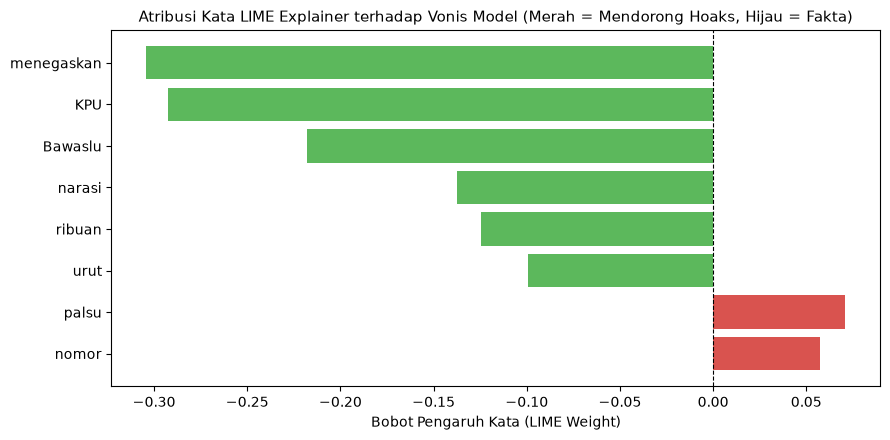

In [3]:
# %% [3] Visualisasi Pengaruh Kata LIME (Explainable AI)
# Kita ambil penjelasan dari kasus hoaks (kasus indeks ke-1)
kasus_hoaks = kasus_uji[1]["teks"]
penjelasan = predictor.predict_and_explain(kasus_hoaks)["explanation"]

kata_tokens = [t["word"] for t in penjelasan["tokens"]]
skor_bobot = [t["weight"] for t in penjelasan["tokens"]]
warna = ["#d9534f" if w > 0 else "#5cb85c" for w in skor_bobot]

plt.figure(figsize=(9, 4.5))
plt.barh(kata_tokens, skor_bobot, color=warna)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title(
    "Atribusi Kata LIME Explainer terhadap Vonis Model (Merah = Mendorong"
    " Hoaks, Hijau = Fakta)",
    fontsize=11,
)
plt.xlabel("Bobot Pengaruh Kata (LIME Weight)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 4: Validasi Kebersihan Teks OCR (clean_ocr_noise)

In [4]:
# %% [4] Uji Ketahanan Derau Teks Hasil Ekstraksi OCR
teks_ocr_mentah = "KPU meng- umumkan bahwa re- kapitulasi suara pil- pres\nsudah selesai 100% tanpa ada kecurangan ."
teks_bersih = predictor.preprocess_pipeline(teks_ocr_mentah)

print("Teks Mentah Hasil OCR :")
print(repr(teks_ocr_mentah))
print("\nTeks Setelah Pipeline (tp-1.6 + OCR Cleaner) :")
print(repr(teks_bersih))

Teks Mentah Hasil OCR :
'KPU meng- umumkan bahwa re- kapitulasi suara pil- pres\nsudah selesai 100% tanpa ada kecurangan .'

Teks Setelah Pipeline (tp-1.6 + OCR Cleaner) :
'KPU meng- umumkan bahwa re- kapitulasi suara pil- pres sudah selesai 100% tanpa ada kecurangan.'
